# NLP em português: o que os clientes reclamam, e como achar a reclamação a tempo

**Pergunta de negócio:** com milhares de avaliações escritas por mês, como identificar automaticamente as negativas (para o atendimento agir rápido) e entender **do que** os clientes reclamam?

**Dados:** 41.753 avaliações com comentário, escritas por clientes da Olist entre 2016 e 2018 ([Brazilian E-Commerce Public Dataset](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce), CC BY-NC-SA 4.0).

**Rótulo:** a própria nota. Avaliações com nota 1–2 são negativas e com 4–5, positivas. As de nota 3 ficam fora do treino e são analisadas à parte.

**Roteiro**
1. Pré-processamento em português (e por que não apagar o "não")
2. Modelos com divisão temporal: treino até abril/2018, teste de maio a agosto/2018
3. O que o modelo aprendeu
4. Do que os clientes reclamam
5. Uso prático: alerta de avaliação negativa
6. Limitações

In [1]:
import re
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, f1_score, precision_recall_curve
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline, make_union

sys.path.insert(0, "..")  # estilo compartilhado do repositório
from comum.estilo import COR, aplicar, br, fonte, subtitulo
from texto import TEMAS, carregar, limpar, normalizar

warnings.filterwarnings("ignore")
aplicar()
FONTE = "Fonte: Olist Brazilian E-Commerce Public Dataset · elaboração: Cézar Bento"

## 1. Dados e pré-processamento

In [2]:
dados = carregar()
print(f"{br(len(dados))} avaliações com texto")
print(dados.nota.value_counts().sort_index().rename("avaliações").to_string())

# Exemplo do pré-processamento: minúsculas, sem acento, sem pontuação, sem palavras vazias, COM negações
exemplo = "Não recebi o produto até agora, péssimo!"
print("\nOriginal:", exemplo)
print("Limpo:   ", limpar(exemplo))
print("Sem negações (como listas prontas de stopwords fariam):", limpar(exemplo, manter_negacoes=False))

41.753 avaliações com texto
nota
1     9179
2     2229
3     3665
4     6034
5    20646

Original: Não recebi o produto até agora, péssimo!
Limpo:    nao recebi produto agora pessimo
Sem negações (como listas prontas de stopwords fariam): recebi produto agora pessimo


In [3]:
# Divisão TEMPORAL: o modelo aprende com o passado e é avaliado em meses que nunca viu,
# como aconteceria em produção. Uma divisão aleatória misturaria períodos e daria uma nota otimista.
rotulados = dados[dados.negativa.notna()].copy()
rotulados["texto_limpo"] = rotulados.texto.map(limpar)
rotulados["texto_sem_neg"] = rotulados.texto.map(lambda t: limpar(t, manter_negacoes=False))
CORTE = pd.Timestamp("2018-05-01")
treino, teste = rotulados[rotulados.data < CORTE], rotulados[rotulados.data >= CORTE]
print(f"Treino: {br(len(treino))} avaliações ({treino.negativa.mean():.0%} negativas)")
print(f"Teste:  {br(len(teste))} avaliações ({teste.negativa.mean():.0%} negativas)")

Treino: 27.529 avaliações (32% negativas)
Teste:  10.559 avaliações (26% negativas)


## 2. Modelos

Três abordagens clássicas sobre TF-IDF, mais um experimento: a mesma regressão logística, porém **apagando as negações**, como faria uma lista pronta de *stopwords*. Métrica principal: **F1 da classe negativa** (equilíbrio entre achar as reclamações e não gerar alarme falso), com PR-AUC como apoio.

In [4]:
palavras = lambda: TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True)
caracteres = lambda: TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=5, sublinear_tf=True)
logistica = lambda: LogisticRegression(max_iter=3000, C=4, class_weight="balanced")

experimentos = {
    "Naive Bayes (palavras)": (make_pipeline(palavras(), MultinomialNB()), "texto_limpo"),
    "Regressão logística (palavras)": (make_pipeline(palavras(), logistica()), "texto_limpo"),
    "Regressão logística (palavras + caracteres)": (make_pipeline(make_union(palavras(), caracteres()), logistica()), "texto_limpo"),
    "Regressão logística SEM negações": (make_pipeline(palavras(), logistica()), "texto_sem_neg"),
}
linhas, prob = [], {}
for nome, (modelo, coluna) in experimentos.items():
    modelo.fit(treino[coluna], treino.negativa)
    p = modelo.predict_proba(teste[coluna])[:, 1]
    prob[nome] = p
    linhas.append({"modelo": nome, "F1 (negativas)": f1_score(teste.negativa, p >= 0.5),
                   "PR-AUC": average_precision_score(teste.negativa, p)})
resultado = pd.DataFrame(linhas).set_index("modelo")
print(resultado.round(3).to_string())

                                             F1 (negativas)  PR-AUC
modelo                                                             
Naive Bayes (palavras)                                0.871   0.914
Regressão logística (palavras)                        0.875   0.923
Regressão logística (palavras + caracteres)           0.874   0.926
Regressão logística SEM negações                      0.855   0.908


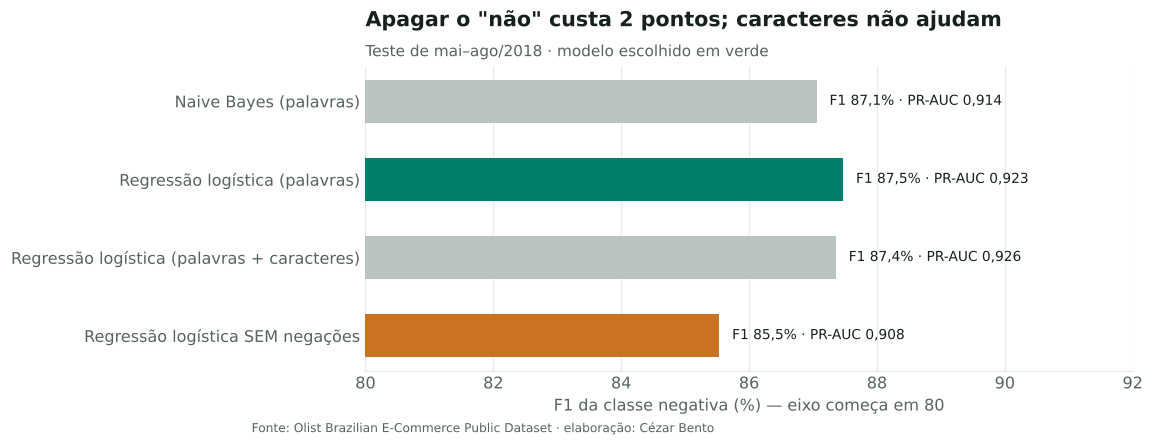

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.6))
r = resultado.iloc[::-1]
cores = [COR["destaque"] if "SEM" in n else (COR["principal"] if n == "Regressão logística (palavras)" else COR["contexto"])
         for n in r.index]
ax.barh(r.index, r["F1 (negativas)"] * 100, color=cores, height=0.55)
for i, (f1, pr) in enumerate(zip(r["F1 (negativas)"], r["PR-AUC"])):
    ax.text(f1 * 100 + 0.2, i, f"F1 {br(f1 * 100, 1)}% · PR-AUC {br(pr, 3)}", va="center", fontsize=9, color=COR["texto"])
ax.set_xlim(80, 92); ax.grid(axis="y", visible=False); ax.set_xlabel("F1 da classe negativa (%) — eixo começa em 80")
ax.set_title("Apagar o \"não\" custa 2 pontos; caracteres não ajudam")
subtitulo(ax, "Teste de mai–ago/2018 · modelo escolhido em verde")
fonte(fig, FONTE)
fig.savefig("figuras/01_modelos.png")

**Escolha:** regressão logística com palavras. Ela empata com a versão que adiciona caracteres, mas é mais simples e interpretável. O experimento confirma que **manter as negações vale 2 pontos de F1** — um detalhe de pré-processamento em português que listas prontas de *stopwords* costumam errar.

## 3. O que o modelo aprendeu

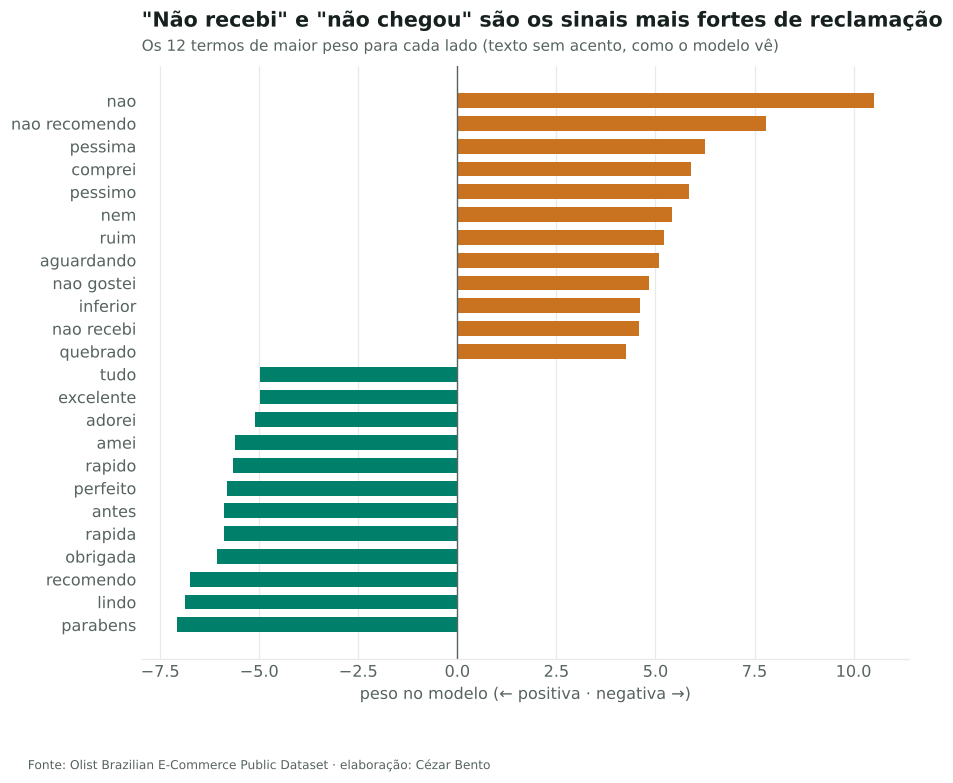

In [6]:
modelo = experimentos["Regressão logística (palavras)"][0]
vocab = modelo.named_steps["tfidfvectorizer"].get_feature_names_out()
coef = pd.Series(modelo.named_steps["logisticregression"].coef_[0], index=vocab)
top = pd.concat([coef.nsmallest(12), coef.nlargest(12)]).sort_values()

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top.index, top.values, color=[COR["destaque"] if v > 0 else COR["principal"] for v in top.values], height=0.65)
ax.axvline(0, color=COR["texto2"], lw=0.9); ax.grid(axis="y", visible=False)
ax.set_xlabel("peso no modelo (← positiva · negativa →)")
ax.set_title("\"Não recebi\" e \"não chegou\" são os sinais mais fortes de reclamação")
subtitulo(ax, "Os 12 termos de maior peso para cada lado (texto sem acento, como o modelo vê)")
fonte(fig, FONTE)
fig.savefig("figuras/02_termos.png")

## 4. Do que os clientes reclamam

Entrega (não recebeu ou atraso): 36.1% · ao menos um tema: 57.9%


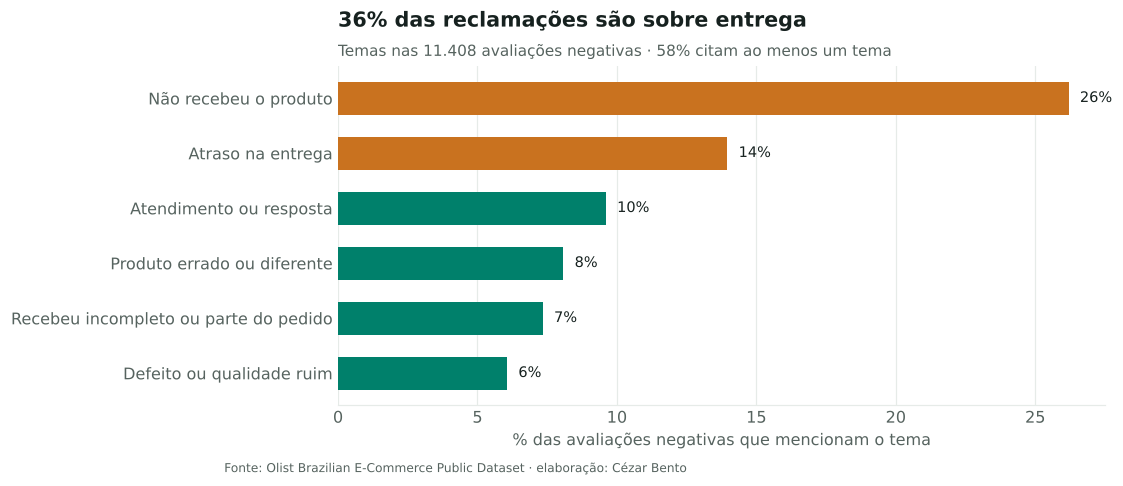

In [7]:
# Temas definidos por expressões simples e auditáveis (ver texto.py). Uma avaliação pode ter mais de um tema.
negativas = dados[dados.negativa == 1].copy()
negativas["norm"] = negativas.texto.map(normalizar)
temas = pd.Series({t: negativas.norm.str.contains(rx).mean() for t, rx in TEMAS.items()}).sort_values()
algum = negativas.norm.map(lambda s: any(re.search(rx, s) for rx in TEMAS.values())).mean()
entrega = negativas.norm.str.contains(TEMAS["Não recebeu o produto"] + "|" + TEMAS["Atraso na entrega"]).mean()

fig, ax = plt.subplots(figsize=(9, 4))
cores = [COR["destaque"] if t in ("Não recebeu o produto", "Atraso na entrega") else COR["principal"] for t in temas.index]
ax.barh(temas.index, temas * 100, color=cores, height=0.6)
for i, v in enumerate(temas):
    ax.text(v * 100 + 0.4, i, f"{br(v * 100)}%", va="center", fontsize=9.5, color=COR["texto"])
ax.grid(axis="y", visible=False); ax.set_xlabel("% das avaliações negativas que mencionam o tema")
ax.set_title(f"{br(entrega * 100)}% das reclamações são sobre entrega")
subtitulo(ax, f"Temas nas {br(len(negativas))} avaliações negativas · {br(algum * 100)}% citam ao menos um tema")
fonte(fig, FONTE)
fig.savefig("figuras/03_temas.png")
print(f"Entrega (não recebeu ou atraso): {entrega:.1%} · ao menos um tema: {algum:.1%}")

Isso conversa com o [projeto de previsão de demanda](https://github.com/cezarcobaink/previsao-demanda-olist), em que um atraso de 4 a 7 dias derruba a nota média de 4,2 para 2,3: **a logística é a principal alavanca de satisfação**, muito antes do produto em si.

## 5. Uso prático: alerta de avaliação negativa

O atendimento quer ver quase todas as reclamações. Escolho o limiar que garante **90% de recall** (pegar 9 de cada 10 negativas) e meço quanto do volume de alertas é reclamação de fato.

Limiar: 0.61 · recall 90% · precisão 85% · alertas em 27% das avaliações


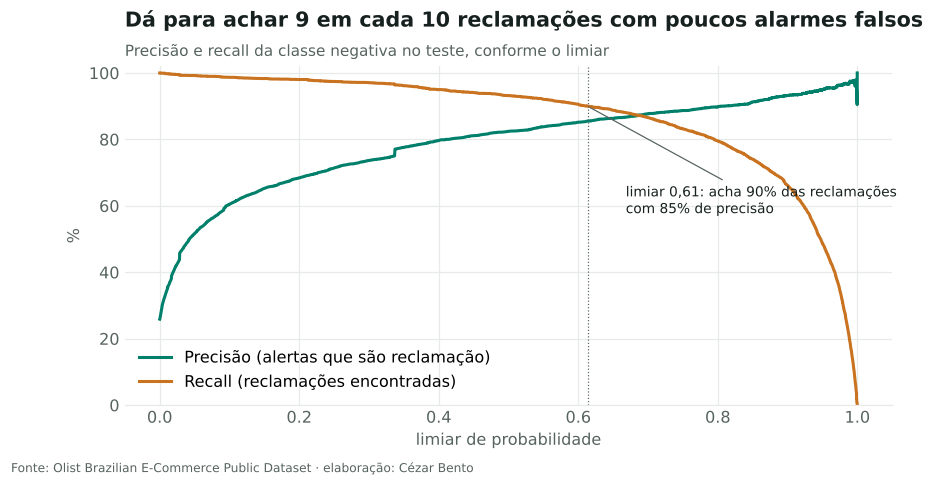

In [8]:
p = prob["Regressão logística (palavras)"]
precisao, recall, limiares = precision_recall_curve(teste.negativa, p)
i = np.where(recall[:-1] >= 0.90)[0][-1]   # maior limiar que ainda mantém recall >= 90%
limiar, prec_90 = limiares[i], precisao[i]
alertas = (p >= limiar).mean()
print(f"Limiar: {limiar:.2f} · recall {recall[i]:.0%} · precisão {prec_90:.0%} · alertas em {alertas:.0%} das avaliações")

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(limiares, precisao[:-1] * 100, color=COR["principal"], lw=2, label="Precisão (alertas que são reclamação)")
ax.plot(limiares, recall[:-1] * 100, color=COR["destaque"], lw=2, label="Recall (reclamações encontradas)")
ax.axvline(limiar, color=COR["texto2"], lw=0.8, ls=":")
ax.annotate(f"limiar {br(limiar, 2)}: acha 90% das reclamações\ncom {br(prec_90 * 100)}% de precisão",
            (limiar, 90), xytext=(25, -70), textcoords="offset points", fontsize=9, color=COR["texto"],
            arrowprops=dict(arrowstyle="-", color=COR["texto2"], lw=0.8))
ax.set_xlabel("limiar de probabilidade"); ax.set_ylabel("%"); ax.set_ylim(0, 102); ax.legend(loc="lower left")
ax.set_title("Dá para achar 9 em cada 10 reclamações com poucos alarmes falsos")
subtitulo(ax, "Precisão e recall da classe negativa no teste, conforme o limiar")
fonte(fig, FONTE)
fig.savefig("figuras/04_alerta.png")

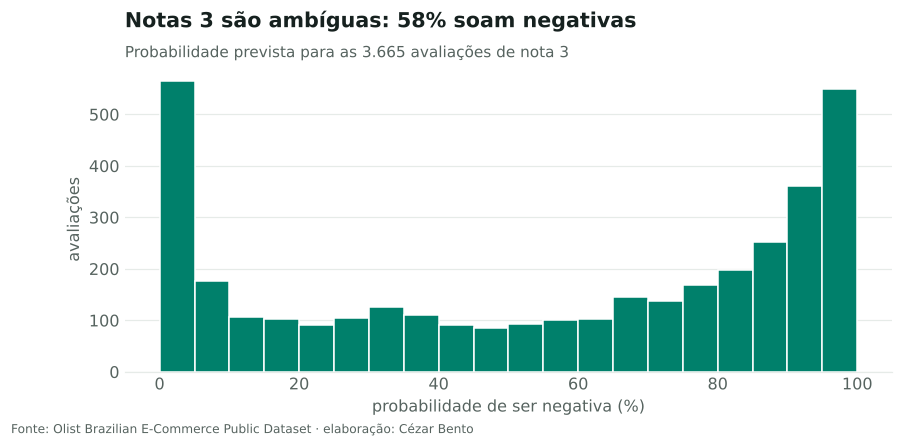

In [9]:
# E as avaliações de nota 3 (fora do treino)? O modelo as vê como mistas: a distribuição é espalhada.
neutras = dados[dados.nota == 3].copy()
p3 = modelo.predict_proba(neutras.texto.map(limpar))[:, 1]
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.hist(p3 * 100, bins=20, color=COR["principal"], edgecolor="white")
ax.set_xlabel("probabilidade de ser negativa (%)"); ax.set_ylabel("avaliações"); ax.grid(axis="x", visible=False)
ax.set_title(f"Notas 3 são ambíguas: {br((p3 >= 0.5).mean() * 100)}% soam negativas")
subtitulo(ax, f"Probabilidade prevista para as {br(len(neutras))} avaliações de nota 3")
fonte(fig, FONTE)
fig.savefig("figuras/05_neutras.png")

## 6. Limitações e próximos passos
- **Rótulo pela nota:** há clientes que dão nota 5 com texto crítico, e vice-versa; o rótulo herda esse ruído.
- **Temas por expressões:** são auditáveis e explicáveis, mas não pegam paráfrases. O próximo passo é comparar com um **LLM** classificando o tema (zero-shot) numa amostra validada manualmente, medindo custo × ganho.
- **Mudança de vocabulário:** gírias e produtos novos exigem retreino periódico; a divisão temporal já mede essa degradação.